# R3 결과 살펴보기 (재학습 없음)

이 노트북은 저장소에 커밋된 **작은 결과표만** 읽습니다. 세포 배열·GPU·서버 자산이 필요 없습니다(pandas, matplotlib만 필요).
저장소 루트에서 실행하세요: `jupyter nbconvert --to notebook --execute tutorials/anchored_distribution_r3/01_inspect_results.ipynb`

순서: ① 분포 신호 진단과 gate → ② 평균 예측기 선택 → ③ dev에서의 복원 규칙 비교 → ④ 동결 후 held-out 약물 평가 → ⑤ SNU-423.

ED = Energy distance(작을수록 실제 처리군 세포에 가까움). 평균을 고정한 방법은 표본을 자기 평균으로 중심화하므로 값이 0보다 작을 수 있습니다.
방법끼리의 **차이**를 읽으세요.

In [1]:
import json, os
from pathlib import Path
import pandas as pd
ROOT = Path.cwd() if (Path.cwd() / "reports").exists() else Path.cwd().parents[1]
T = ROOT / "reports/anchored_distribution_r3/tables"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("tables:", sorted(p.name for p in T.iterdir()))

tables: ['d1_ctrl_wells.tsv', 'd1_summary.json', 'd1_wells_train.tsv.gz', 'dev_c1_restoration.tsv', 'dev_r31_baselines.tsv', 'final_all_lines.tsv', 'final_snu423.tsv', 'mean_model_cv.tsv']


## ① 진단 D1/D2와 gate

`G1`은 "정답 평균으로 옮긴 대조군"이 "같은 조건의 다른 well"보다 실제 처리군에서 얼마나 더 먼가입니다. 구간 하한이 0보다 커야 통과입니다.

In [2]:
d = json.loads((T / "d1_summary.json").read_text())
keys = ["all.a", "all.c_raw", "all.e_raw", "all.M_e_raw_minus_c_raw", "multi.b", "multi.d_mm", "multi.e_mm",
        "multi.G1_H_b_minus_d_mm", "multi.G1_ratio_H_over_a_minus_d_mm", "multi.G2_e_mm_minus_d_mm", "all.b_half_minus_c_mm"]
g = pd.DataFrame([{**{"quantity": k}, **d[k]} for k in keys]).round(4)
print(g.to_string(index=False))
G1 = d["multi.G1_H_b_minus_d_mm"]; M = d["all.M_e_raw_minus_c_raw"]
print()
print("M  (metric separates real-real from shuffled):", "PASS" if M["lo"] > 0 else "FAIL")
print("G1 (shape headroom beyond replicate wells):   ", "PASS" if G1["lo"] > 0 else "FAIL  -> generator claim on hold")

                          quantity     est      lo      hi  n_drugs
                             all.a  0.6045  0.5035  0.7242      208
                         all.c_raw -0.0008 -0.0035  0.0019      208
                         all.e_raw  0.6867  0.6016  0.7901      208
           all.M_e_raw_minus_c_raw  0.6875  0.6033  0.7907      208
                           multi.b -0.7030 -0.7437 -0.6579       26
                        multi.d_mm -0.6799 -0.7102 -0.6431       26
                        multi.e_mm -0.7492 -0.7840 -0.7127       26
           multi.G1_H_b_minus_d_mm -0.0231 -0.0727  0.0249       26
multi.G1_ratio_H_over_a_minus_d_mm -0.0209 -0.0681  0.0217       26
          multi.G2_e_mm_minus_d_mm -0.0693 -0.1161 -0.0281       26
             all.b_half_minus_c_mm  0.1745  0.1303  0.2200      208

M  (metric separates real-real from shuffled): PASS
G1 (shape headroom beyond replicate wells):    FAIL  -> generator claim on hold


## ② 공통 평균 예측기 (train 약물 내부 3-fold CV)

In [3]:
print(pd.read_csv(T / "mean_model_cv.tsv", sep="\t")[["kind", "hp", "rmse_cond", "rmse_cond_folds"]].round(5).to_string(index=False))
print(json.loads((ROOT / "configs/anchored_distribution_r3/mean_model.json").read_text()))

    kind                                                                   hp  rmse_cond                rmse_cond_folds
nochange                                                                   {}    0.10279 [0.106944, 0.100262, 0.101159]
linemean                                                                   {}    0.09165 [0.094093, 0.091624, 0.089224]
     krr                                                        {"lam": 0.03}    0.09369 [0.096122, 0.093449, 0.091493]
     krr                                                         {"lam": 0.1}    0.09328 [0.095647, 0.093144, 0.091056]
     krr                                                         {"lam": 0.3}    0.09259  [0.094877, 0.09258, 0.090323]
     krr                                                         {"lam": 1.0}    0.09174 [0.093977, 0.091839, 0.089401]
     krr                                                         {"lam": 3.0}    0.09140 [0.093683, 0.091494, 0.089035]
krr_line                                

## ③ dev: 비음수 복원 전 / v1 / v2

같은 평균 μ̂, 같은 세포 수, 같은 복원을 쓰는 기준선들입니다.

In [4]:
def show(name, variants=("pre", "anchored", "anchored2")):
    R = pd.read_csv(T / name, sep="\t")
    R[["m", "variant"]] = R.method.str.split(":", expand=True)
    R = R[R.variant.isin(variants) | (R.variant == "native")]
    cols = ["method", "n_drugs", "n_conditions", "ed", "ed_lo", "ed_hi", "ed_pca50", "mean_rmse", "var_ratio", "zero_frac_mae", "cluster_tv"]
    print(R[cols].round(4).to_string(index=False))
    return R
dev = show("dev_c1_restoration.tsv")

                          method  n_drugs  n_conditions      ed   ed_lo   ed_hi  ed_pca50  mean_rmse  var_ratio  zero_frac_mae  cluster_tv
                  gauss_lr50:pre       79           625 -0.1098 -0.1798 -0.0265    0.6200     0.1363     0.9956         0.4489      0.1742
            gauss_lr50:anchored2       79           625 -0.1019 -0.1752 -0.0138    0.7326     0.1362     1.0576         0.0615      0.1830
                  gauss_diag:pre       79           625 -0.1016 -0.1717 -0.0182    2.0798     0.1363     0.9955         0.4489      0.4195
                shifted_pool:pre       79           625 -0.1006 -0.1732 -0.0152    0.5881     0.1363     1.0013         0.4098      0.1622
            gauss_diag:anchored2       79           625 -0.0967 -0.1705 -0.0083    2.0135     0.1362     1.0576         0.0615      0.4122
          shifted_pool:anchored2       79           625 -0.0961 -0.1653 -0.0143    0.5991     0.1362     1.1215         0.0610      0.1645
               shifted:anch

## ④ 동결 후 held-out 약물 평가 (전체 적격 세포주)

재사용 공개 벤치마크에서의 동결 후 평가입니다. DDPM·CellFlow는 gate에 따라 이 평가에 넣지 않았습니다(사후 pilot은 ⑥).

In [5]:
fin = show("final_all_lines.tsv")
ref = "shifted:anchored2"
c = [k for k in fin.columns if k.startswith("d_ed_vs_" + ref)]
print()
print("paired difference vs shifted control (frozen restoration v2), drug-block bootstrap:")
print(fin[fin.variant == "anchored2"][["method"] + c].round(4).to_string(index=False))

                          method  n_drugs  n_conditions      ed   ed_lo   ed_hi  ed_pca50  mean_rmse  var_ratio  zero_frac_mae  cluster_tv
                  gauss_lr50:pre       70          3333 -0.0714 -0.1715  0.0667    0.5687     0.1384     1.0036         0.4471      0.1732
               shifted:anchored2       70          3333 -0.0711 -0.1738  0.0710    0.5552     0.1383     1.0725         0.0592      0.1674
          shifted_pool:anchored2       70          3333 -0.0698 -0.1713  0.0724    0.5541     0.1383     1.1090         0.0598      0.1674
            gauss_lr50:anchored2       70          3333 -0.0694 -0.1714  0.0713    0.6794     0.1383     1.0467         0.0603      0.1794
                shifted_pool:pre       70          3333 -0.0685 -0.1698  0.0722    0.5375     0.1384     1.0045         0.4049      0.1612
shifted@delta_linemean:anchored2       70          3333 -0.0665 -0.1718  0.0765    0.5735     0.1387     1.0728         0.0592      0.1691
            gauss_diag:anch

## ⑤ SNU-423 (사전 지정 HCC 적용 대상, 별도 보고)

In [6]:
snu = show("final_snu423.tsv", variants=("anchored2",))
c = [k for k in snu.columns if k.startswith("d_ed_vs_shifted:anchored2")]
print(snu[snu.variant == "anchored2"][["method"] + c].round(4).to_string(index=False))

                          method  n_drugs  n_conditions     ed   ed_lo  ed_hi  ed_pca50  mean_rmse  var_ratio  zero_frac_mae  cluster_tv
               shifted:anchored2       70            70 0.0120 -0.1301 0.2054    0.6254     0.1414     1.0483         0.0675      0.1784
          shifted_pool:anchored2       70            70 0.0128 -0.1246 0.2080    0.6011     0.1414     1.0926         0.0682      0.1776
            gauss_lr50:anchored2       70            70 0.0148 -0.1251 0.2068    0.7372     0.1414     1.0373         0.0686      0.2004
shifted@delta_linemean:anchored2       70            70 0.0179 -0.1261 0.2150    0.6423     0.1418     1.0485         0.0675      0.1826
            gauss_diag:anchored2       70            70 0.0206 -0.1200 0.2128    2.3291     0.1414     1.0374         0.0686      0.4322
          shifted@zero:anchored2       70            70 0.1595 -0.0078 0.3748    0.7821     0.1510     1.0510         0.0678      0.1843
                  control:native       70

## ⑥ 사용자 승인 사후 pilot: 생성기 (탐색적)

사전 지정 gate G1은 실패했고 생성기 주장은 보류됐습니다. 아래는 그 뒤 사용자 승인으로 실행한 **탐색적** pilot입니다(계획된 확증 시험이 아님).
기준선의 시험 점수를 이미 본 뒤에 설계했으므로 재사용 벤치마크를 두 번째로 본 것입니다. 원형(native) 표와 평균 고정 표를 따로 봅니다.

In [ ]:
def pilot(name):
    R = pd.read_csv(T / name, sep="\t")
    R[["m", "variant"]] = R.method.str.split(":", expand=True)
    return R

def native_table(R):
    S = R[(R.variant == "native")]
    print(S[["method", "n_drugs", "n_seed_runs", "ed", "ed_lo", "ed_hi", "ed_pca50", "mean_rmse", "var_ratio", "neg_frac",
             "d_ed_vs_control:native", "d_ed_vs_control:native_lo", "d_ed_vs_control:native_hi"]].round(4).to_string(index=False))

def matched_table(R, keep=("shifted", "shifted_pool", "gauss_lr50", "ddpm_resid", "ddpm_abs", "cellflow")):
    S = R[R.m.str.startswith(keep) & ~R.m.str.contains("@") & (R.variant != "native")]
    P = S.pivot(index="m", columns="variant", values="ed").rename(columns={"pre": "before", "anchored": "v1", "anchored2": "v2"})
    print(P.round(4).to_string())
    A = S[S.variant == "anchored2"]
    c = [k for k in A.columns if k.startswith(("d_ed_vs_shifted:anchored2", "d_ed_vs_gauss_lr50:anchored2"))]
    print(); print("restoration v2, paired difference (positive = worse than the reference):")
    print(A[["method", "n_seed_runs", "ed", "ed_lo", "ed_hi"] + c].round(4).to_string(index=False))

dev = pilot("pilot_dev.tsv")
print("DEV (train-fold drugs, 8 lines) -- native"); native_table(dev)
print(); print("DEV -- mean-matched"); matched_table(dev, keep=("shifted", "gauss_lr50", "ddpm_resid", "ddpm_abs", "cellflow"))

### pilot held-out (시험 약물 70개): 전체 세포주, 그리고 SNU-423

In [ ]:
for name, title in [("pilot_final_all_lines.tsv", "ALL CELL LINES"), ("pilot_final_snu423.tsv", "SNU-423")]:
    R = pilot(name)
    print("=" * 20, title, "-- native"); native_table(R)
    print(); print(title, "-- mean-matched"); matched_table(R); print()
ts = pd.read_csv(T / "pilot_final_by_train_seed.tsv", sep="\t")
print("per training seed (all lines):")
print(ts[ts.method.str.endswith((":anchored2", ":native"))][["method", "ed", "ed_lo", "ed_hi"]].round(4).to_string(index=False))

fig1_gate_diagnostics.png


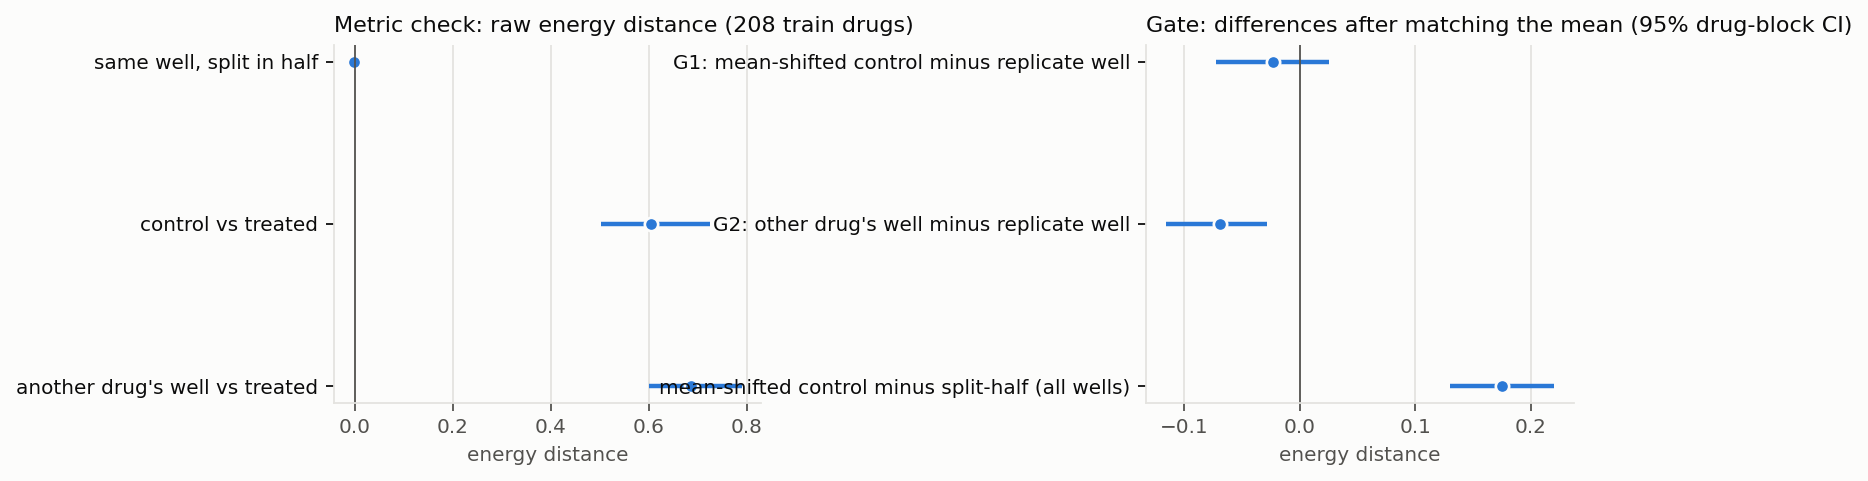

fig2_dev_restoration.png


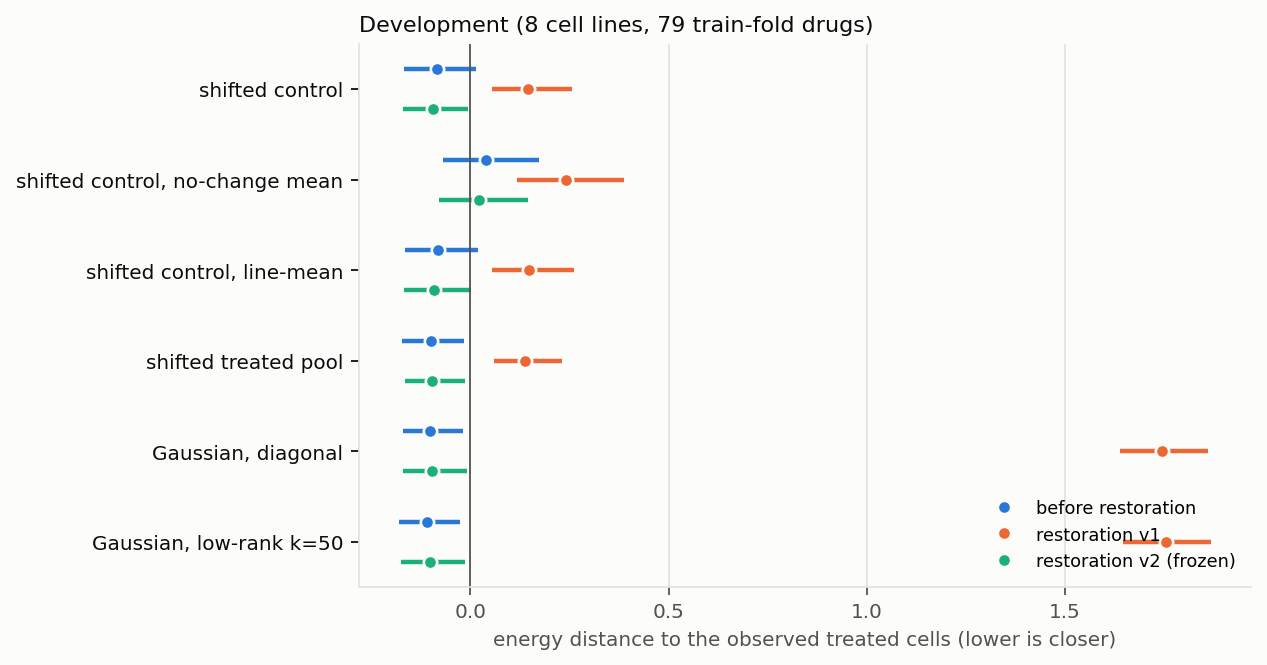

fig3_final_all_lines.png


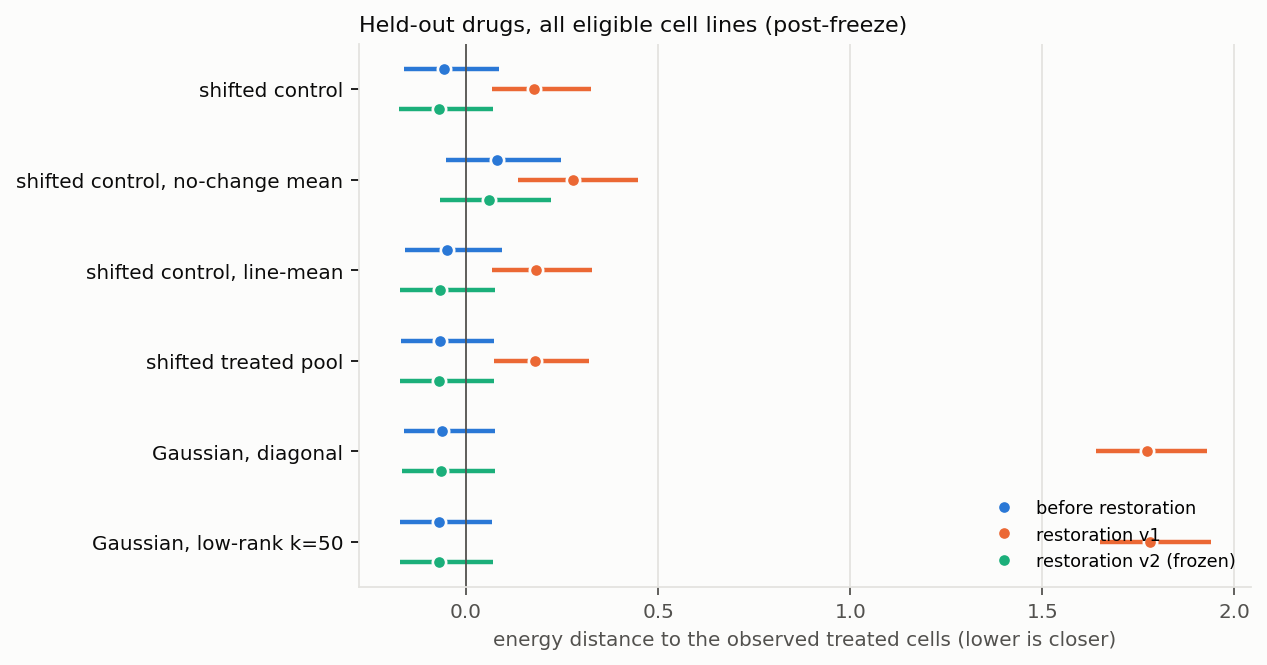

fig3b_final_zoom.png


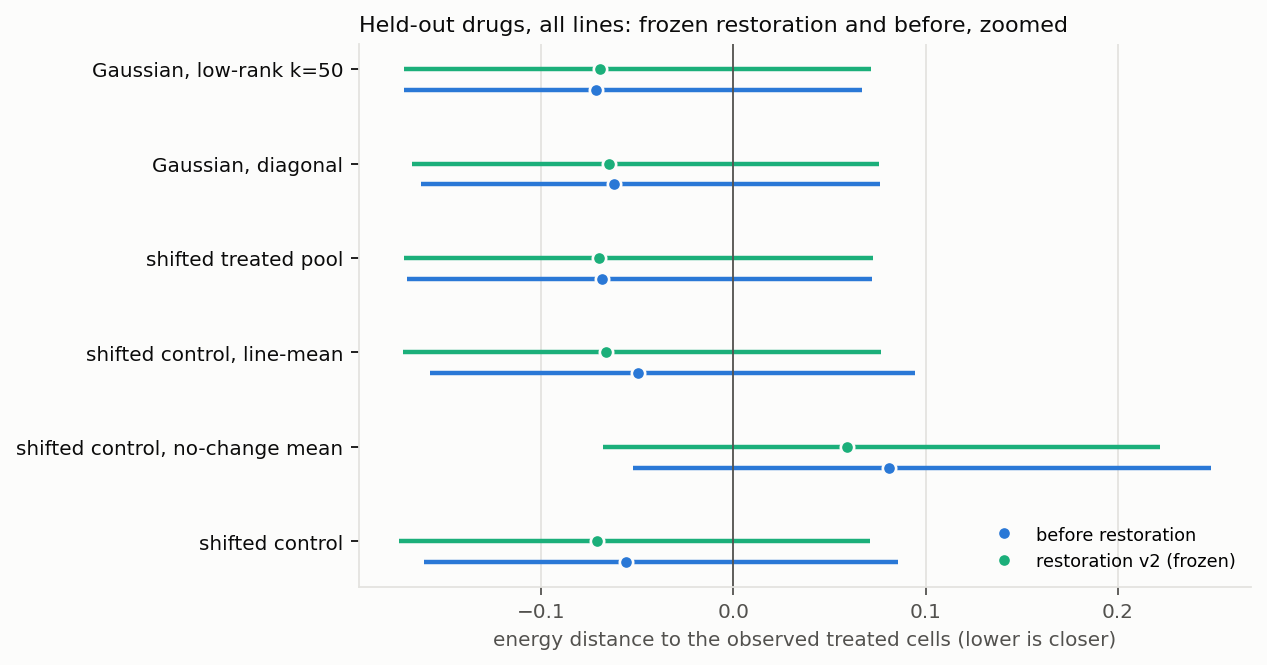

fig4_final_snu423.png


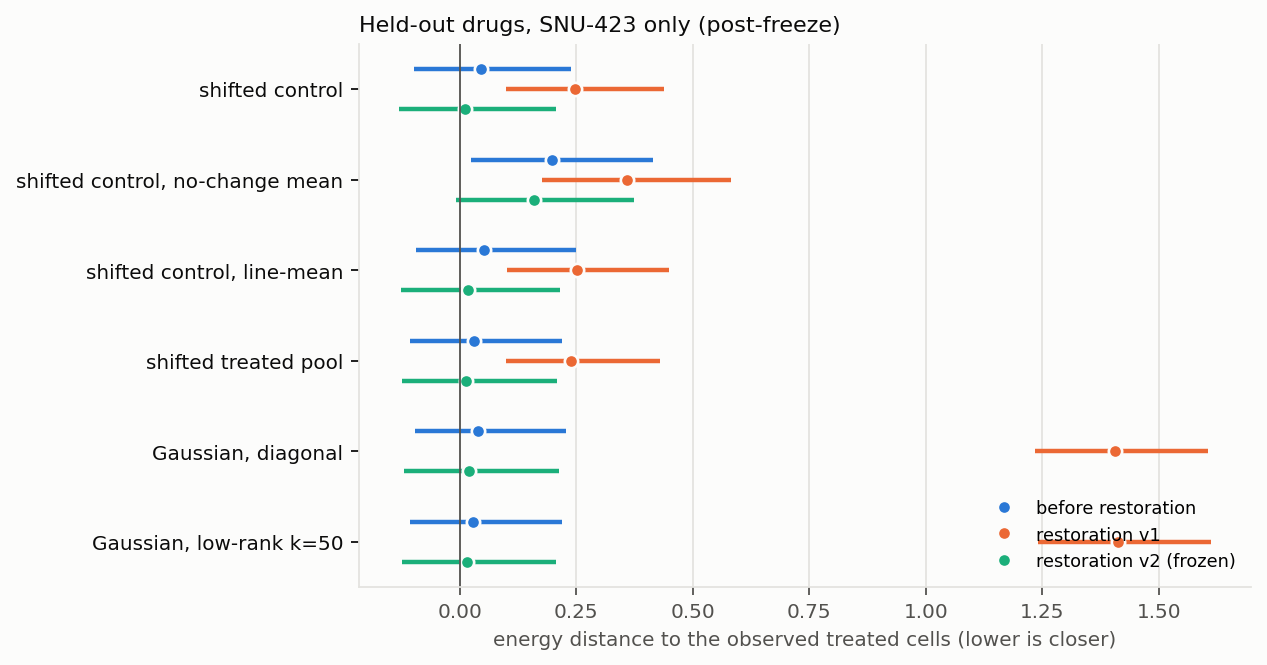

fig5_final_zero_variance.png


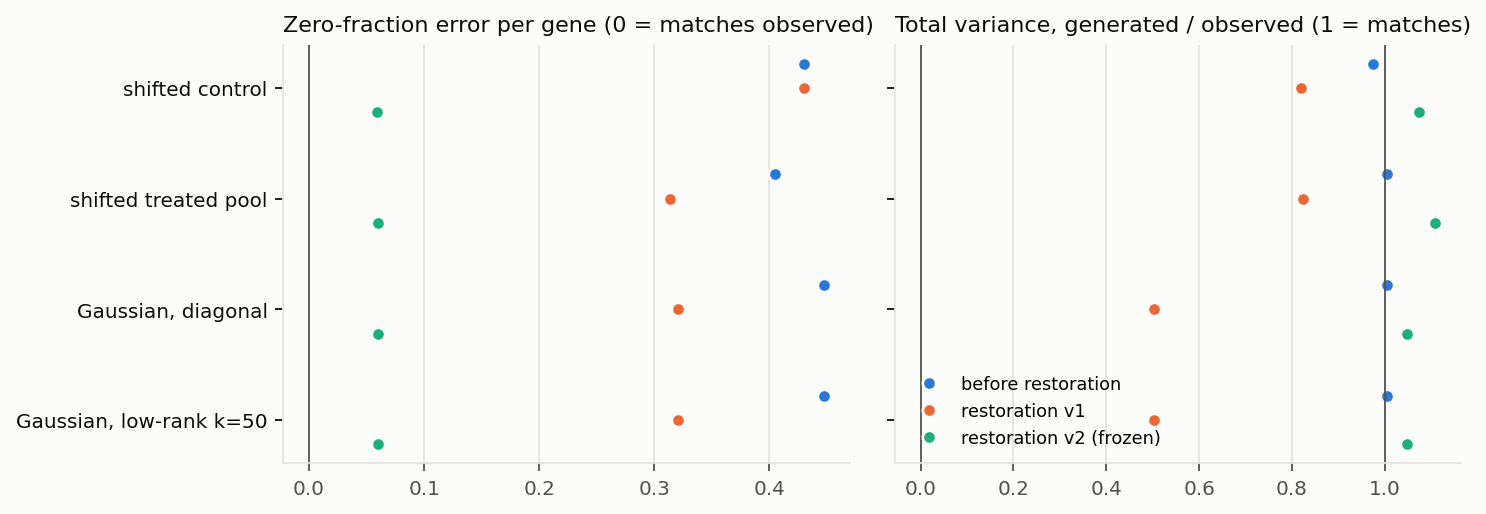

In [7]:
from IPython.display import Image, display
for f in sorted((ROOT / "reports/anchored_distribution_r3/figures").glob("*.png")):
    print(f.name); display(Image(filename=str(f), width=760))